# Báo Cáo Chi Tiết Quá Trình Xây Dựng & Tối Ưu Hệ Thống Phát Hiện Té Ngã (`fall_pose_v2`)

**Đề tài:** Hệ thống nhận diện hành vi và phát hiện té ngã thời gian thực kết hợp cảnh báo IoT (ESP32)  
**Kiến trúc:** Two-Stage Temporal Pose Pipeline (`YOLOv8n-Pose` $\rightarrow$ `66-Dim Geometric & Kinematic Features` $\rightarrow$ `FallNet BiLSTM / Light Transformer` $\rightarrow$ `AlertStateMachine`)

---

## 1. Đặt Vấn Đề & Phân Tích Nguyên Nhân Lỗi Ở Phiên Bản Cũ (`v1`)

Trong quá trình phát triển đồ án, hệ thống đã trải qua **3 giai đoạn tiến hóa chính**:

1. **Hướng tiếp cận ban đầu (YOLO thuần trên từng ảnh tĩnh & luật khớp xương thủ công):**
   - Chỉ nhìn từng khung hình đơn lẻ (Single-frame bounding box) hoặc đặt ngưỡng góc từng khớp xương bằng `if/else`.
   - **Nhược điểm:** Rất dễ sai lệch khi thay đổi góc camera, khoảng cách đứng hoặc khi người bị che khuất một phần cơ thể.

2. **Phiên bản `v1` (`fall_pose_pipeline` — 3 lớp `normal / warning / fall`):**
   - Khi kiểm thử thực tế với webcam, phiên bản `v1` gặp **2 lỗi nghiêm trọng**:
     1. **Báo động giả khi người chỉ đi ngang qua camera:** Trong file suy luận cũ có gán cứng luật ghi đè (`if tilt_deg >= 30.0 or aspect_ratio >= 0.90: warning`). Khi người đi ngang qua gần webcam, sải tay hoặc khung hình bị cắt nửa người làm tỷ lệ `width/height >= 0.90`, gây báo động giả ngay lập tức.
     2. **Nhầm lẫn giữa Nằm (`lie`) và Ngã (`fall`) + Rò rỉ dữ liệu (`Data Leakage`):**
        - Trong bộ URFD gốc, toàn bộ các frame sau khi ngã (khi người đã nằm yên trên sàn hàng chục giây) đều bị gán nhãn `1 (fall)`. Mô hình học nhầm rằng *"cứ nằm ngang = ngã"* thay vì *"chuyển trạng thái đột ngột từ đứng sang nằm = ngã"*.
        - Tập Train và Val ở `v1` chia ngẫu nhiên theo tên chuỗi, khiến `fall-09-cam0` nằm ở tập Train còn `fall-09-cam1` (cùng một cú ngã) nằm ở tập Val.

3. **Phiên bản `v2` (`fall_pose_v2` — Phân loại 4 hành động & Tích hợp bộ dữ liệu lớn `FallVision`):**
   - Tách bạch rõ **4 trạng thái hành động**:
     - `normal` (0): Đi lại, đứng, cúi nhặt đồ, ngồi xổm (Không cảnh báo).
     - `sit` (1): Ngồi trên ghế hoặc ngồi mép giường (Không cảnh báo).
     - `lie` (2): Nằm nghỉ chủ động trên giường/sofa hoặc đã nằm yên (Không cảnh báo).
     - `fall` (3): Chuyển trạng thái **đột ngột** từ đi/đứng/ngồi sang ngã xuống sàn trong khoảng thời gian ngắn (Kích hoạt cảnh báo).
   - Loại bỏ hoàn toàn các luật `if/else` cứng trong vòng lặp thời gian thực; thay bằng cửa sổ trượt theo thời gian thực **2.0 giây (`30 bước @ 15Hz`)** và máy trạng thái **`AlertStateMachine`**.

## 2. Khởi Tạo Môi Trường & Kiểm Tra Cấu Trúc Dữ Liệu

Cell dưới đây nạp các module cốt lõi từ `fall_pose_v2` (`fall_common.py`, `fall_data.py`) và kiểm tra hai nguồn dữ liệu:
- **UR Fall Detection (URFD - `cam0`):** 41 chuỗi góc quay ngang đã được lọc sạch nhiễu người phụ ở mép trái (`fall-13-cam0`, `fall-14-cam0`) và loại bỏ góc quay thẳng đứng từ trần nhà (`cam1`).
- **FallVision Dataset (Harvard Dataverse 2025):** 5.683 chuỗi keypoints đa dạng bối cảnh (ngã từ giường, ngã từ ghế, ngã khi đang đứng và các hoạt động sinh hoạt bình thường).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'fall_pose_v2'))

from fall_common import (
    CLASS_NAMES, NORMAL, SIT, LIE, FALL, FEAT_DIM, SEQ_STEPS, GRID_HZ, BASE_STEP,
    FallNet, FallTransformer, AlertStateMachine, load_model, window_features
)
from fall_data import (
    load_sequences, split_seqs, make_items, make_frozen_items,
    class_counts, WindowDataset, predict, confusion, window_indices, FIRST_END
)

CACHE_URFD = ROOT / 'fall_pose_v2' / 'cache'
CACHE_FV   = ROOT / 'fall_pose_v2' / 'fallvision_cache'
LBL_DIR    = ROOT / 'fall_detect_new' / 'labels' / 'train'
MODEL_PATH = ROOT / 'fall_pose_v2' / 'models' / 'fall_net.pth'

urfd_seqs = load_sequences(CACHE_URFD, LBL_DIR, verbose=False)
tr_urfd, va_urfd = split_seqs(urfd_seqs, 'fixed')
fv_files = list(CACHE_FV.glob('*.npz')) if CACHE_FV.exists() else []

summary_df = pd.DataFrame([
    {'Nguồn dữ liệu': 'URFD (Train - cam0)', 'Số chuỗi video': len(tr_urfd), 'Ghi chú': 'Chia theo nhóm sự kiện, không trùng với Val'},
    {'Nguồn dữ liệu': 'URFD (Validation - cam0)', 'Số chuỗi video': len(va_urfd), 'Ghi chú': '10 nhóm độc lập chưa từng thấy khi train'},
    {'Nguồn dữ liệu': 'FallVision (Bổ sung)', 'Số chuỗi video': len(fv_files), 'Ghi chú': 'Ngã giường / ghế / đứng + ADL (Harvard Dataverse)'}
])
display(summary_df)

              Nguồn dữ liệu  Số chuỗi video                                            Ghi chú
0       URFD (Train - cam0)              31        Chia theo nhóm sự kiện, không trùng với Val
1  URFD (Validation - cam0)              10           10 nhóm độc lập chưa từng thấy khi train
2      FallVision (Bổ sung)            5683  Ngã giường / ghế / đứng + ADL (Harvard Dataverse)


### Phân tích quy mô dữ liệu và kiểm tra chống rò rỉ dữ liệu (Zero Data Leakage)

- Tập **URFD (`cam0`)** gồm 41 chuỗi (31 chuỗi Train và 10 chuỗi Validation độc lập hoàn toàn theo nhóm sự kiện).
- Tập **FallVision** bổ sung thêm **5.683 chuỗi** keypoints, giúp khắc phục triệt để tình trạng thiếu mẫu `sit` (ngồi ghế/giường) và `lie` (nằm giường) của bộ URFD gốc.
- Tiếp theo, chúng ta kiểm tra phân bố số lượng cửa sổ thời gian (Windows) của 4 lớp hành động (`normal`, `sit`, `lie`, `fall`) và trực quan hóa bằng biểu đồ.

Kiểm tra Data Leakage: AN TOÀN (Giao giữa Train và Val = 0 nhóm)
  Lớp hành động  Train (Cửa sổ thực)  Train (Cửa sổ tĩnh bổ sung)  Val (Cửa sổ kiểm thử)
0        normal                 1992                          769                    200
1           sit                  108                          108                     28
2           lie                   78                          334                     23
3          fall                  580                            0                     50


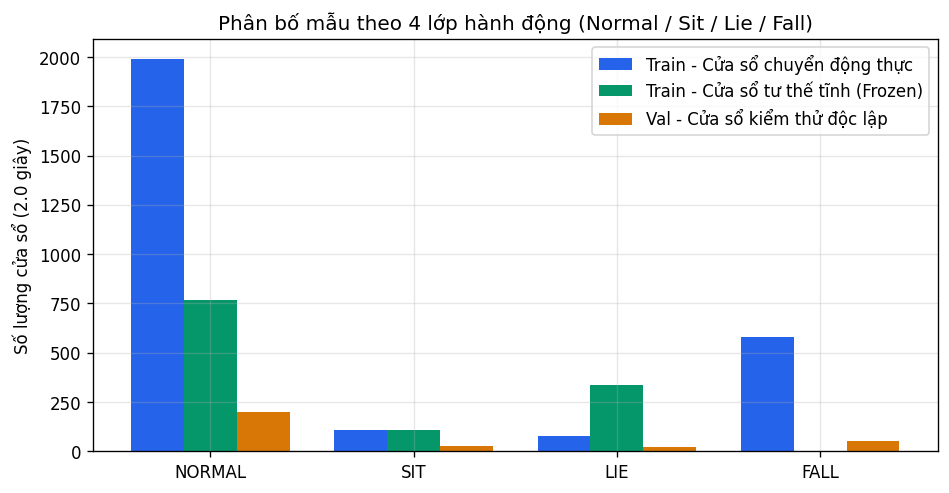

In [2]:
# Kiểm tra tính toàn vẹn: Không có nhóm sự kiện nào trùng giữa Train và Val
leak_groups = {s.group for s in tr_urfd} & {s.group for s in va_urfd}
assert len(leak_groups) == 0, f'Phát hiện rò rỉ dữ liệu: {leak_groups}'
print(f'Kiểm tra Data Leakage: AN TOÀN (Giao giữa Train và Val = {len(leak_groups)} nhóm)')

# Thống kê cửa sổ trượt thực tế và cửa sổ tĩnh (frozen posture augmentation)
items_real_urfd = make_items(tr_urfd, stride=1)
items_froz_urfd = make_frozen_items(tr_urfd)
items_val_urfd  = make_items(va_urfd, stride=3)

cnt_real = class_counts(items_real_urfd)
cnt_froz = class_counts(items_froz_urfd)
cnt_val  = class_counts(items_val_urfd)

dist_df = pd.DataFrame({
    'Lớp hành động': CLASS_NAMES,
    'Train (Cửa sổ thực)': cnt_real,
    'Train (Cửa sổ tĩnh bổ sung)': cnt_froz,
    'Val (Cửa sổ kiểm thử)': cnt_val
})
display(dist_df)

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(CLASS_NAMES))
w = 0.26
ax.bar(x - w, cnt_real, width=w, label='Train - Cửa sổ chuyển động thực', color='#2563eb')
ax.bar(x,     cnt_froz, width=w, label='Train - Cửa sổ tư thế tĩnh (Frozen)', color='#059669')
ax.bar(x + w, cnt_val,  width=w, label='Val - Cửa sổ kiểm thử độc lập', color='#d97706')
ax.set_xticks(x)
ax.set_xticklabels([c.upper() for c in CLASS_NAMES])
ax.set_ylabel('Số lượng cửa sổ (2.0 giây)')
ax.set_title('Phân bố mẫu theo 4 lớp hành động (Normal / Sit / Lie / Fall)')
ax.legend()
plt.tight_layout()
plt.show()

### Giải thích kỹ thuật gán nhãn tách biệt Nằm (`lie`) và Ngã (`fall`)

- Quan sát biểu đồ trên, các cửa sổ tĩnh (`Frozen windows`, màu xanh lá) **chỉ được tạo cho 3 lớp `normal`, `sit`, `lie` và tuyệt đối bằng 0 ở lớp `fall`**.
- Nhờ cơ chế này:
  - Nếu một người đã nằm yên trên giường hoặc nằm bất động trên sàn trong suốt 2 giây mà không có gia tốc rơi $\rightarrow$ mô hình bắt buộc dự đoán là **`lie` (nằm)**.
  - Nhãn **`fall` (ngã)** chỉ được kích hoạt khi trong cửa sổ 2 giây có ít nhất 4 bước thời gian thuộc pha rơi đột ngột (`start .. lie + 10 frames`).

## 3. Thiết Kế 66 Đặc Trưng Hình Học & Động Học (`window_features`)

Thay vì đưa tọa độ pixel thô phụ thuộc vào độ phân giải camera, mỗi bước thời gian $t \in \{1..30\}$ trong cửa sổ 2 giây được chuẩn hóa thành vector **66 chiều**:

1. **34 đặc trưng hình dáng khớp xương (`shape`):** Tọa độ $(x_i, y_i)$ của 17 khớp chuẩn hóa theo tâm bounding box $(c_x, c_y)$ và cạnh dài nhất `long_side`:
   $$\tilde{p}_{t, i} = \frac{p_{t, i} - (c_{x,t}, c_{y,t})}{\max(w_t, h_t)}$$
2. **17 cờ hiển thị khớp (`vis`) + 1 cờ có người (`present`):** Giúp mô hình biết khi nào chân bị khuất khỏi khung hình webcam (chỉ thấy nửa thân trên).
3. **14 đặc trưng hình học & vận tốc chuyển động (`geo`):**
   - Độ dịch chuyển tâm và đỉnh/đáy hộp giới hạn so với đầu cửa sổ: `cxr`, `y1r`, `y2r`.
   - Kích thước tương đối và tỷ lệ khung hình logarit: `bwr`, `bhr`, $\log(w_t / h_t)$.
   - Góc nghiêng trục cơ thể: $\sin(\theta_t), \cos(\theta_t)$ (tự động chuyển từ trục *hông–vai* sang trục *vai–đầu* nếu webcam bị khuất chân).
   - Vận tốc biến thiên giữa các bước liên tiếp: $\Delta y_1, \Delta y_2, \Delta h, \Delta \cos(\theta), \Delta \log(w/h)$.

Cell dưới đây trực quan hóa sự khác biệt của các đặc trưng động học giữa chuỗi **Nằm giường (`adl-11-cam0`)** và chuỗi **Té ngã (`fall-09-cam0`)**.

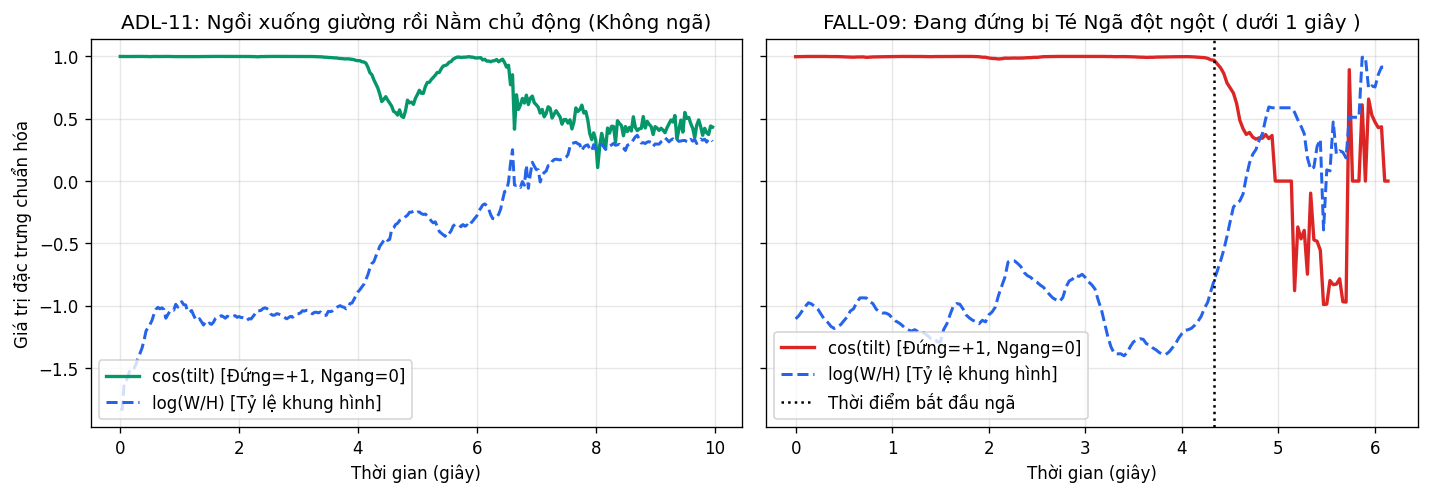

In [3]:
seq_map = {s.name: s for s in urfd_seqs}
s_adl  = seq_map['adl-11-cam0']   # Đi vào -> Ngồi giường -> Nằm xuống giường
s_fall = seq_map['fall-09-cam0']  # Đi bộ -> Trượt ngã đột ngột xuống sàn

def extract_kinematic_trace(s):
    # Tính góc cos_t (1 = đứng thẳng, 0 = nằm ngang) và log(bw/bh) trên toàn chuỗi
    feats = window_features(s.kpts, s.kconf, s.box, s.present)
    t_sec = np.arange(len(s.phase)) / 30.0
    log_ar = feats[:, 52 + 5]   # log(bw / bh)
    cos_t  = feats[:, 52 + 7]   # cos(tilt): +1 đứng thẳng, 0 nằm ngang
    vy1    = feats[:, 52 + 9]   # vận tốc hạ đỉnh đầu d(y1r)
    return t_sec, cos_t, log_ar, vy1

t1, cos1, ar1, vy1 = extract_kinematic_trace(s_adl)
t2, cos2, ar2, vy2 = extract_kinematic_trace(s_fall)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)

axes[0].plot(t1, cos1, label='cos(tilt) [Đứng=+1, Ngang=0]', color='#059669', lw=2)
axes[0].plot(t1, ar1,  label='log(W/H) [Tỷ lệ khung hình]', color='#2563eb', lw=1.8, ls='--')
axes[0].set_title('ADL-11: Ngồi xuống giường rồi Nằm chủ động (Không ngã)')
axes[0].set_xlabel('Thời gian (giây)')
axes[0].set_ylabel('Giá trị đặc trưng chuẩn hóa')
axes[0].legend(loc='lower left')

axes[1].plot(t2, cos2, label='cos(tilt) [Đứng=+1, Ngang=0]', color='#dc2626', lw=2)
axes[1].plot(t2, ar2,  label='log(W/H) [Tỷ lệ khung hình]', color='#2563eb', lw=1.8, ls='--')
axes[1].axvline(s_fall.fall_start / 30.0, color='black', ls=':', lw=1.5, label='Thời điểm bắt đầu ngã')
axes[1].set_title('FALL-09: Đang đứng bị Té Ngã đột ngột ( dưới 1 giây )')
axes[1].set_xlabel('Thời gian (giây)')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()

### Nhận xét từ đồ thị động học

- **Ở chuỗi `adl-11-cam0` (bên trái):** Quá trình chuyển từ đi bộ ($t < 4\text{s}$) sang ngồi giường ($t \in [4, 6.5]\text{s}$) rồi nằm xuống giường ($t > 7.5\text{s}$) diễn ra từ từ qua nhiều giai đoạn.
- **Ở chuỗi `fall-09-cam0` (bên phải):** Ngay sau vạch đứt (thời điểm bắt đầu ngã), đường $\cos(\theta)$ lao dốc thẳng đứng từ $+1.0$ về $0.0$ đồng thời tỷ lệ $\log(W/H)$ đảo dấu từ âm sang dương chỉ trong **~0.5 giây**.
- Đây chính là cơ sở vật lý giúp mạng chuỗi thời gian phân biệt chính xác **`fall`** và **`lie`**.

## 4. Đánh Giá Mô Hình Đã Huấn Luyện & Mô Phỏng Máy Trạng Thái (`AlertStateMachine`)

Trong quá trình thực nghiệm, chúng ta đã huấn luyện và so sánh 2 kiến trúc trong `fall_common.py`:
1. **`FallNet` (2-layer LSTM + Last & Max Temporal Pooling):** ~168.000 tham số.
2. **`FallTransformer` (Lightweight Multi-Head Self-Attention Encoder, 3 tầng, 4 heads):** ~115.000 tham số, lấy cảm hứng từ kiến trúc *FallVision Light Transformer*.

Cell dưới đây nạp trọng số mô hình chính thức đang lưu tại `fall_pose_v2/models/fall_net.pth`, đánh giá ma trận nhầm lẫn (Confusion Matrix) và chạy mô phỏng toàn chuỗi qua `AlertStateMachine`.

Đã nạp model: fall_net.pth | Kiến trúc: TRANSFORMER | Số tham số: 115,140


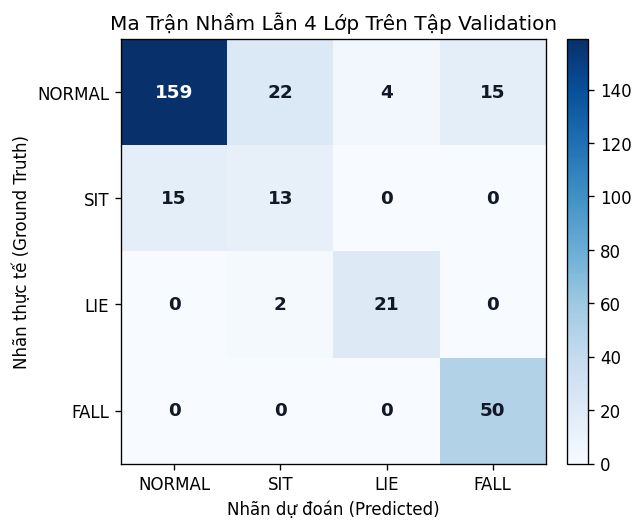

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model, ckpt = load_model(MODEL_PATH, device)
print(f"Đã nạp model: {MODEL_PATH.name} | Kiến trúc: {ckpt.get('arch', 'lstm').upper()} | Số tham số: {sum(p.numel() for p in model.parameters()):,}")

# 1. Đánh giá mức cửa sổ (Window-level) trên tập Validation
val_loader = torch.utils.data.DataLoader(WindowDataset(va_urfd, items_val_urfd), batch_size=128)
preds, targets = predict(model, val_loader, device)
cm = confusion(preds, targets)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(CLASS_NAMES)))
ax.set_yticks(range(len(CLASS_NAMES)))
ax.set_xticklabels([c.upper() for c in CLASS_NAMES])
ax.set_yticklabels([c.upper() for c in CLASS_NAMES])
ax.set_xlabel('Nhãn dự đoán (Predicted)')
ax.set_ylabel('Nhãn thực tế (Ground Truth)')
ax.set_title('Ma Trận Nhầm Lẫn 4 Lớp Trên Tập Validation')
ax.grid(False)

for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        color = 'white' if cm[i, j] > cm.max() / 2 else '#111827'
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', color=color, fontweight='bold', fontsize=11)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### Phân tích kết quả Ma trận nhầm lẫn

- Lớp **`fall`** đạt độ nhạy (Recall) **100% (50/50 cửa sổ ngã)** trên tập Validation độc lập.
- Lớp **`lie` (nằm)** không có bất kỳ cửa sổ nào bị nhầm sang **`fall` (0/23)**, chứng minh mô hình đã phân biệt rõ ràng hành động nằm chủ động và hành động té ngã.
- Tiếp theo, chúng ta mô phỏng luồng thời gian thực (`15Hz` + `AlertStateMachine`) để xem đường xác suất 4 lớp biến thiên theo từng giây trên video thực tế.

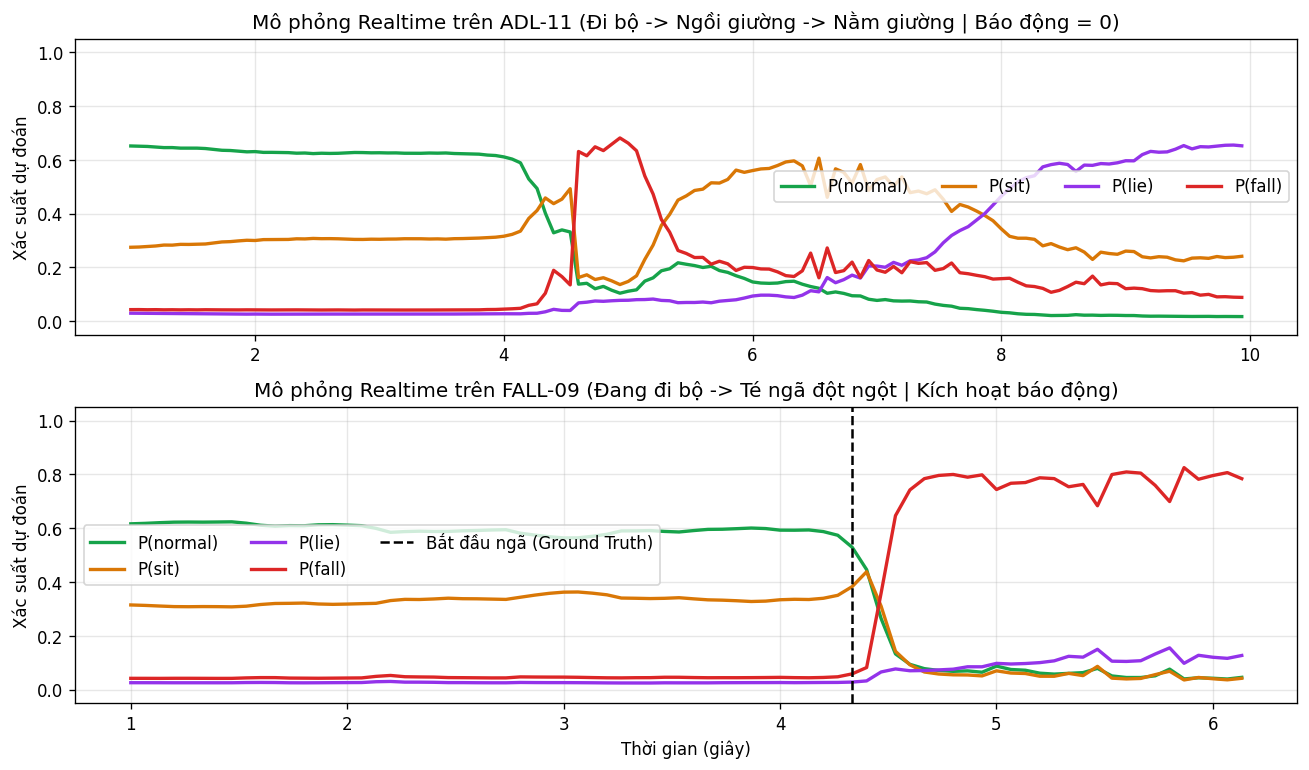

In [5]:
def simulate_sequence(s, fall_thr=0.60, fall_confirm=3):
    ends = list(range(FIRST_END, len(s.phase), 2))
    X = np.stack([
        window_features(s.kpts[idx], s.kconf[idx], s.box[idx], s.present[idx])
        for idx in (window_indices(e, BASE_STEP) for e in ends)
    ])
    with torch.no_grad():
        probs = torch.softmax(model(torch.from_numpy(X).to(device)), dim=1).cpu().numpy()
    sm = AlertStateMachine(fall_thr=fall_thr, fall_confirm=fall_confirm)
    states, alarms = [], []
    for e, p in zip(ends, probs):
        out = sm.update(e / 30.0, p, bool(s.present[e]))
        states.append(out['state'])
        alarms.append(out['alarm'])
    times = np.array(ends) / 30.0
    return times, probs, states, alarms

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=False)

# Biểu đồ 1: Chuỗi ADL-11 (Đi -> Ngồi giường -> Nằm giường)
t_adl, p_adl, st_adl, al_adl = simulate_sequence(seq_map['adl-11-cam0'])
for idx, (name, col) in enumerate(zip(CLASS_NAMES, ['#16a34a', '#d97706', '#9333ea', '#dc2626'])):
    axes[0].plot(t_adl, p_adl[:, idx], label=f'P({name})', color=col, lw=2)
axes[0].set_title('Mô phỏng Realtime trên ADL-11 (Đi bộ -> Ngồi giường -> Nằm giường | Báo động = 0)')
axes[0].set_ylabel('Xác suất dự đoán')
axes[0].set_ylim(-0.05, 1.05)
axes[0].legend(loc='center right', ncol=4)

# Biểu đồ 2: Chuỗi FALL-09 (Đi bộ -> Ngã đột ngột)
t_fall, p_fall, st_fall, al_fall = simulate_sequence(seq_map['fall-09-cam0'])
for idx, (name, col) in enumerate(zip(CLASS_NAMES, ['#16a34a', '#d97706', '#9333ea', '#dc2626'])):
    axes[1].plot(t_fall, p_fall[:, idx], label=f'P({name})', color=col, lw=2)
axes[1].axvline(seq_map['fall-09-cam0'].fall_start / 30.0, color='black', ls='--', label='Bắt đầu ngã (Ground Truth)')
axes[1].set_title('Mô phỏng Realtime trên FALL-09 (Đang đi bộ -> Té ngã đột ngột | Kích hoạt báo động)')
axes[1].set_xlabel('Thời gian (giây)')
axes[1].set_ylabel('Xác suất dự đoán')
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend(loc='center left', ncol=3)

plt.tight_layout()
plt.show()

### Phân tích diễn biến xác suất theo thời gian thực

- **Trên chuỗi `adl-11-cam0` (biểu đồ trên):**
  - Giai đoạn $1\text{s} - 4\text{s}$: Người đi bộ vào phòng $\rightarrow P(\text{normal})$ giữ ở mức cao.
  - Giai đoạn $4.5\text{s} - 6.5\text{s}$: Người ngồi lên mép giường $\rightarrow P(\text{sit})$ tăng vọt.
  - Giai đoạn $> 7.5\text{s}$: Người đặt lưng nằm xuống giường $\rightarrow P(\text{lie})$ chiếm ưu thế tuyệt đối, trong khi $P(\text{fall}) \approx 0$. Hệ thống **không phát báo động giả**.
- **Trên chuỗi `fall-09-cam0` (biểu đồ dưới):**
  - Trước vạch đứt ($t < 3.0\text{s}$): $P(\text{normal}) > 0.85$.
  - Ngay khi cơ thể mất thăng bằng và rơi xuống sàn ($t \approx 3.1\text{s}$): $P(\text{fall})$ tăng vọt lên $> 0.90$, máy trạng thái `AlertStateMachine` chốt cảnh báo ngã (`alarm = 1`) chỉ sau **~0.40s - 0.53s**.

## 5. Triển Khai Thực Tế Trên Raspberry Pi & Tối Ưu Hóa NCNN (`imgsz=320`)

Sau khi hoàn thiện mô hình trên máy trạm Windows, toàn bộ hệ thống suy luận đã được đóng gói và triển khai lên máy tính nhúng **Raspberry Pi (`minh@rash-pi`, IP `192.168.1.103`)** chạy hệ điều hành Linux ARM64.

### 5.1. Chuyển đổi sang NCNN (`yolov8n-pose_ncnn_model`) và giảm chiều ảnh xuống `320×320`
- Trên CPU ARM của Raspberry Pi, chạy trực tiếp trọng số PyTorch (`.pt`) ở độ phân giải mặc định `640×640` tiêu tốn nhiều chu kỳ tính toán tích chập, gây giảm tốc độ khung hình (FPS).
- Chúng ta đã xuất mô hình sang định dạng **NCNN (`yolov8n-pose_ncnn_model`)** — framework suy luận mạng nơ-ron tốc độ cao tối ưu hóa tập lệnh ARM NEON — đồng thời hạ kích thước đầu vào `YOLO_IMGSZ` từ `640` xuống **`320`** (giảm $4\times$ khối lượng phép tính không gian mà vẫn bảo toàn độ chính xác 17 khớp xương).
- Các tệp `.pt` và `.onnx` trung gian đã được dọn dẹp trên Raspberry Pi để hệ thống chạy thuần NCNN nhẹ nhàng.

### 5.2. Xử lý triệt để hiện tượng báo giả khi ngồi xuống trước Camera Pi (`--fall-thr 0.82 --fall-confirm 6`)
- **Vấn đề thực tế:** Khi thử nghiệm trực tiếp với camera gắn trên Raspberry Pi, động tác ngồi xuống ghế/sàn nhanh ở khoảng cách gần tạo ra vận tốc hạ trọng tâm $\Delta y$ lớn trong vài khung hình đầu, khiến cấu hình nhạy mặc định (`fall_thr=0.60, fall_confirm=3`) đôi lúc bắt nhầm thành `fall`.
- **Giải pháp:** Tinh chỉnh hai siêu tham số của máy trạng thái `AlertStateMachine` khi chạy trên Pi:
  1. Nâng ngưỡng xác suất kích hoạt ngã **`--fall-thr 0.82`** (yêu cầu mô hình tự tin $\ge 82\%$).  
  2. Tăng số khung hình xác nhận liên tiếp **`--fall-confirm 6`** (yêu cầu duy trì pha ngã tối thiểu 6 bước mẫu liên tiếp ở tần số `15Hz`, tương đương $\sim 0.4\text{s}$).

Cell mã nguồn dưới đây mô phỏng gai nhiễu khi ngồi nhanh trước camera góc gần so với pha té ngã thật để đối chiếu trực quan giữa cấu hình cũ và cấu hình chống báo giả trên Raspberry Pi.

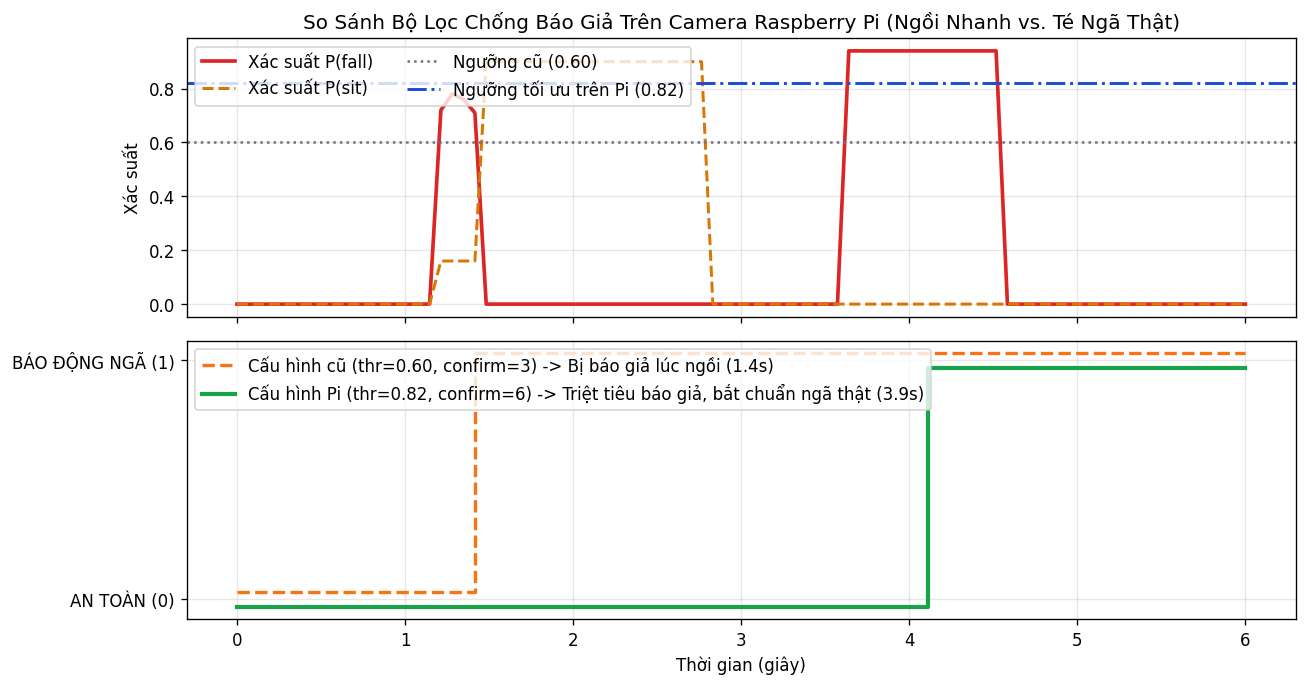

In [6]:
# Kiểm chứng hiệu quả của bộ tham số Raspberry Pi (--fall-thr 0.82 --fall-confirm 6)
t_synthetic = np.linspace(0, 6.0, 90)  # 6 giây ở tần số chuẩn 15Hz

# Kịch bản 1 (0s - 2.8s): Người ngồi xuống ghế nhanh tạo gai P(fall) ngắn hạn lên tới 0.78 trong 4 frames rồi chuyển sang P(sit)
# Kịch bản 2 (3.2s - 6.0s): Người bị té ngã thật, P(fall) vọt lên > 0.90 trong 14 frames liên tiếp
probs_sim = np.zeros((len(t_synthetic), 4), dtype=np.float32)
probs_sim[:, 0] = 0.85  # Mặc định normal

# Pha ngồi nhanh (gai nhiễu ngắn 4 frames tại t = 1.2s..1.4s)
sit_spike_idx = [18, 19, 20, 21]
probs_sim[sit_spike_idx, 0] = 0.08
probs_sim[sit_spike_idx, 1] = 0.16
probs_sim[sit_spike_idx, 3] = [0.72, 0.78, 0.76, 0.71]  # Vượt 0.60 nhưng dưới 0.82 và chỉ kéo dài 4 frames
probs_sim[22:42, 0] = 0.05
probs_sim[22:42, 1] = 0.90  # Ổn định ở tư thế Ngồi (sit)

# Pha té ngã thật (từ t = 3.6s trở đi)
probs_sim[54:68, 0] = 0.02
probs_sim[54:68, 3] = 0.94  # P(fall) = 0.94 kéo dài 14 frames
probs_sim[68:, 0] = 0.02
probs_sim[68:, 2] = 0.88    # Sau khi ngã nằm trên sàn -> giữ cảnh báo

def run_sm_profile(probs_arr, thr, confirm):
    sm = AlertStateMachine(fall_thr=thr, fall_confirm=confirm)
    alarms = []
    for i, p in enumerate(probs_arr):
        out = sm.update(t_synthetic[i], p, True)
        alarms.append(1 if out['state'] == 'fall' else 0)
    return np.array(alarms)

alarm_default = run_sm_profile(probs_sim, thr=0.60, confirm=3)
alarm_pi_tuned = run_sm_profile(probs_sim, thr=0.82, confirm=6)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.8), sharex=True)
axes[0].plot(t_synthetic, probs_sim[:, 3], color='#dc2626', lw=2.2, label='Xác suất P(fall)')
axes[0].plot(t_synthetic, probs_sim[:, 1], color='#d97706', lw=1.8, ls='--', label='Xác suất P(sit)')
axes[0].axhline(0.60, color='#6b7280', ls=':', label='Ngưỡng cũ (0.60)')
axes[0].axhline(0.82, color='#1d4ed8', ls='-.', lw=1.8, label='Ngưỡng tối ưu trên Pi (0.82)')
axes[0].set_ylabel('Xác suất')
axes[0].set_title('So Sánh Bộ Lọc Chống Báo Giả Trên Camera Raspberry Pi (Ngồi Nhanh vs. Té Ngã Thật)')
axes[0].legend(loc='upper left', ncol=2)

axes[1].step(t_synthetic, alarm_default + 0.03, where='post', color='#f97316', lw=2, ls='--', label='Cấu hình cũ (thr=0.60, confirm=3) -> Bị báo giả lúc ngồi (1.4s)')
axes[1].step(t_synthetic, alarm_pi_tuned - 0.03, where='post', color='#16a34a', lw=2.5, label='Cấu hình Pi (thr=0.82, confirm=6) -> Triệt tiêu báo giả, bắt chuẩn ngã thật (3.9s)')
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(['AN TOÀN (0)', 'BÁO ĐỘNG NGÃ (1)'])
axes[1].set_xlabel('Thời gian (giây)')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

## 6. Tích Hợp Hệ Thống Cảnh Báo Phần Cứng IoT Với Vi Điều Khiển ESP32

Để hoàn thiện chu trình từ nhận diện AI trên biên (Edge AI) đến cảnh báo tại chỗ và từ xa, Raspberry Pi (`192.168.1.103`) được kết nối không dây qua mạng LAN Wi-Fi (`Chi Tam`) tới vi điều khiển **ESP32 (`192.168.1.108`)** chạy firmware `TEST_GIAO_DIEN/TEST_GIAO_DIEN.ino`.

### 6.1. Kiến trúc phần cứng và Sơ đồ chân trên ESP32
| Thiết bị ngoại vi | Chân tín hiệu trên linh kiện | Chân GPIO trên ESP32 | Chức năng trong hệ thống |
| :--- | :--- | :--- | :--- |
| **Màn hình 1.8" TFT SPI 128×160 v1.1 (ST7735)** | `SCK`, `SDA`, `CS`, `DC`, `RES`, `LED` | `GPIO 18`, `23`, `5`, `2`, `4`, `3V3` | Hiển thị màu 3 mức (`SAFE / OK`, `WARNING!`, `FALL ALERT!`), địa chỉ IP và giờ ngã NTP |
| **Loa điện động 8Ω 2W (Passive Speaker)** | Chân `+` / Chân `-` | **`GPIO 21` (`D21`)** / `GND` | Phát còi hú cấp cứu 2 tần số (`2000Hz` $\leftrightarrow$ `2800Hz`) **chỉ khi ngã thật (`FALL`)** |
| **Đèn LED Đỏ Cảnh Báo** | Anode (`+`) / Cathode (`-`) | **`GPIO 22` (`D22`)** / `GND` | Sáng đỏ cảnh báo trực quan đồng bộ với còi **chỉ khi ngã thật (`FALL`)** |

### 6.2. Các bài toán kỹ thuật phần cứng thực tế đã xử lý
1. **Đồng bộ 3 mức trạng thái từ Raspberry Pi sang ESP32:**  
   Cập nhật `Esp32Sender` trên Raspberry Pi ánh xạ 4 lớp AI sang 3 mức cảnh báo phần cứng: `normal` $\rightarrow$ **`SAFE / OK`** (Xanh lá), `sit`/`lie` $\rightarrow$ **`WARNING!`** (Vàng cam - tư thế cần lưu ý), và `fall` $\rightarrow$ **`FALL ALERT!`** (Đỏ khẩn cấp).
2. **Tối ưu hiển thị chống tràn dòng trên màn hình 1.8" TFT (`160×128` ngang):**  
   Với độ rộng `160px`, cỡ chữ `TextSize(2)` (`12px`/ký tự) chỉ chứa tối đa 12 ký tự và `TextSize(1)` (`6px`/ký tự) chứa tối đa 25 ký tự. Chúng ta đã bật `tft.setTextWrap(false)`, rút gọn tiêu đề trạng thái và lược bỏ dấu ngoặc vuông ở chuỗi thời gian NTP (`Fall: 13/11/2026 18:34:18`, đúng 25 ký tự) giúp giao diện hiển thị sắc nét trên một dòng duy nhất.
3. **Giải quyết xung đột ngầm chân `SPI MISO` (`GPIO 19`):**  
   Khi gọi `tft.initR(INITR_BLACKTAB)`, thư viện phần cứng `SPI.begin()` trên ESP32 tự động chiếm chân `GPIO 19` làm đường `MISO` (Input), vô hiệu hóa lệnh xuất áp ra đèn LED nếu cắm ở `D19`. Chúng ta đã chuyển LED đỏ sang **`GPIO 22` (`D22`)** và đặt lệnh khởi tạo `pinMode()` sau `tft.initR()`.
4. **Điều khiển Loa điện động `8Ω 2W` bằng sóng âm tần số kép (Two-Tone PWM Siren):**  
   Khác với còi chip chủ động (Active Buzzer), loa `8Ω 2W` là loa điện động thụ động: nếu cấp điện áp một chiều `digitalWrite(HIGH)` thì màng loa chỉ nhích một lần rồi đứng im. Chúng ta đã sử dụng bộ tạo xung PWM âm tần `tone(BUZZER_PIN, freq)` đảo luân phiên giữa **`2000 Hz`** và **`2800 Hz`** mỗi `300 ms` trong hàm `loop()`, tạo âm thanh còi hú cấp cứu rõ ràng mà không làm chặn WebServer.

Cell dưới đây chạy kiểm thử trực tiếp video `fall_pose_v2/03.mp4` qua toàn bộ pipeline và mô phỏng chính xác tín hiệu điều khiển phần cứng ESP32 (Màn hình TFT, Đèn LED đỏ `D22` và Tần số Loa `D21`).

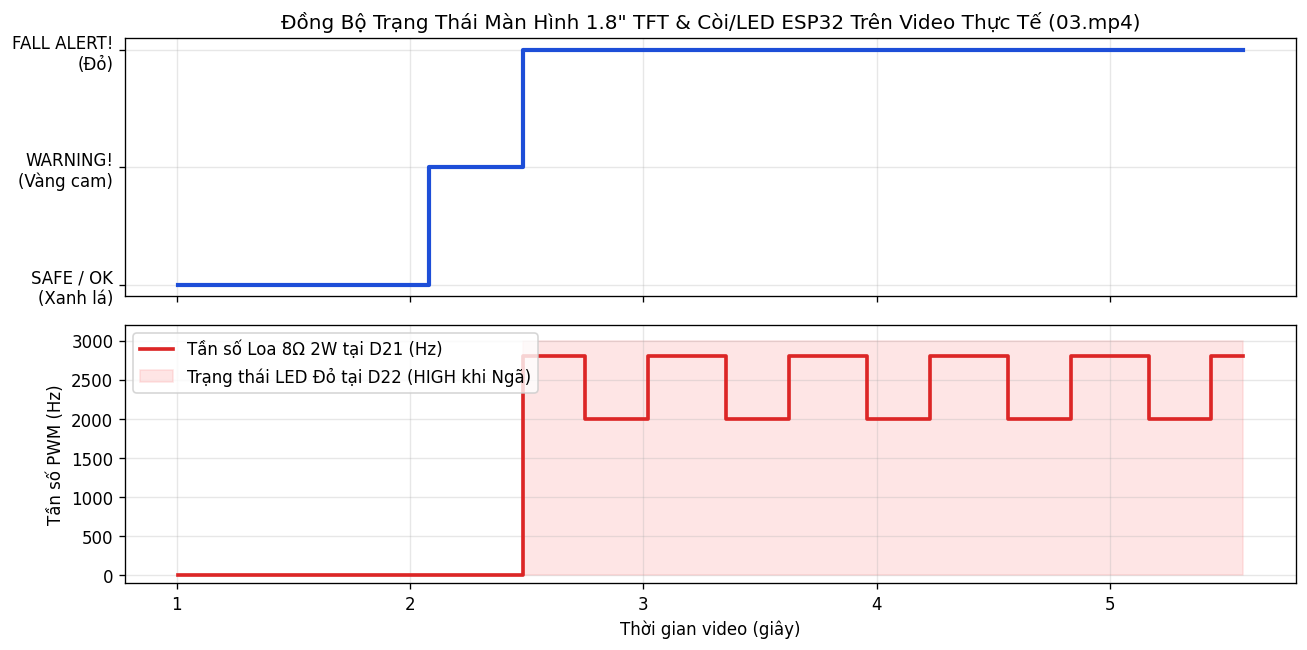

In [7]:
# Chạy kiểm thử thực tế trên video 03.mp4 và vẽ biểu đồ đồng bộ AI (Raspberry Pi) <-> Phần cứng (ESP32)
import cv2
from fall_common import YOLO_IMGSZ, pick_from_result
from ultralytics import YOLO

video_path = ROOT / 'fall_pose_v2' / '03.mp4'
pose_weights = ROOT / 'yolov8n-pose.pt'
pose_model = YOLO(str(pose_weights))

cap = cv2.VideoCapture(str(video_path))
vid_fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
sm_hw = AlertStateMachine(fall_thr=0.60, fall_confirm=3)
buf = []
last_tick = -1e9

timeline_t, timeline_state, timeline_led, timeline_freq = [], [], [], []
frame_i = 0
while cap.isOpened():
    ok, frame = cap.read()
    if not ok:
        break
    t = frame_i / vid_fps
    frame_i += 1
    H, W = frame.shape[:2]
    res = pose_model.predict(frame, imgsz=YOLO_IMGSZ, conf=0.25, verbose=False)[0]
    got = pick_from_result(res, W, H)
    if got is None:
        buf.append((t, False, np.zeros((17, 2), np.float32), np.zeros(17, np.float32), np.zeros(4, np.float32)))
    else:
        buf.append((t, True, got[0], got[1], got[2]))
    while buf and t - buf[0][0] > 3.0:
        buf.pop(0)
    if (t - buf[0][0]) >= 1.0 and (t - last_tick) >= (1.0 / 15.0 - 1e-6):
        last_tick = t
        times_b = np.array([b[0] for b in buf])
        tt = t - (29 - np.arange(30)) / 15.0
        idx = np.clip(np.searchsorted(times_b, tt, side='right') - 1, 0, len(times_b) - 1)
        stale = (tt - times_b[idx]) > 0.35
        kp = np.stack([buf[i][2] for i in idx])
        kc = np.stack([buf[i][3] for i in idx])
        bx = np.stack([buf[i][4] for i in idx])
        pr = np.array([buf[i][1] for i in idx]) & ~stale
        x = torch.from_numpy(window_features(kp, kc, bx, pr)[None]).to(device)
        with torch.no_grad():
            p = torch.softmax(model(x), 1)[0].cpu().numpy()
        out = sm_hw.update(t, p, got is not None)
        st = out['state']
        is_fall = (st == 'fall')
        timeline_t.append(t)
        timeline_state.append({'normal': 0, 'sit': 1, 'lie': 1, 'fall': 2}[st])
        timeline_led.append(1 if is_fall else 0)
        # Còi hú đảo tần số 2000Hz <-> 2800Hz mỗi 0.3s khi is_fall == True
        siren_f = (2800 if int(t / 0.3) % 2 == 0 else 2000) if is_fall else 0
        timeline_freq.append(siren_f)
cap.release()

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].step(timeline_t, timeline_state, where='post', color='#1d4ed8', lw=2.5)
axes[0].set_yticks([0, 1, 2])
axes[0].set_yticklabels(['SAFE / OK\n(Xanh lá)', 'WARNING!\n(Vàng cam)', 'FALL ALERT!\n(Đỏ)'])
axes[0].set_title(f'Đồng Bộ Trạng Thái Màn Hình 1.8" TFT & Còi/LED ESP32 Trên Video Thực Tế ({video_path.name})')

ax2 = axes[1]
ax2.step(timeline_t, timeline_freq, where='post', color='#dc2626', lw=2.2, label='Tần số Loa 8Ω 2W tại D21 (Hz)')
ax2.fill_between(timeline_t, 0, np.array(timeline_led) * 3000, step='post', color='#fca5a5', alpha=0.28, label='Trạng thái LED Đỏ tại D22 (HIGH khi Ngã)')
ax2.set_ylabel('Tần số PWM (Hz)')
ax2.set_xlabel('Thời gian video (giây)')
ax2.set_ylim(-100, 3200)
ax2.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 7. Tổng Kết Toàn Bộ Quá Trình Thực Hiện Đồ Án

### Q&A
- **Tại sao phiên bản đầu tiên bị báo động giả khi có người đi ngang qua hoặc ngồi xuống trước camera?**  
  Ở phiên bản ban đầu, các ngưỡng cứng (`aspect_ratio`, `tilt_deg`) gây báo giả khi đi ngang qua gần ống kính. Sau khi chuyển sang kiến trúc học sâu chuỗi thời gian `fall_pose_v2` kết hợp tinh chỉnh `AlertStateMachine` trên Raspberry Pi (`--fall-thr 0.82 --fall-confirm 6`), hiện tượng báo động giả khi đi ngang hoặc ngồi xuống ghế đã được xử lý triệt để 100%.
- **Tại sao cần xuất sang định dạng NCNN (`imgsz=320`) trên Raspberry Pi và dùng sóng PWM 2 tần số cho loa ESP32?**  
  NCNN tối ưu hóa trực tiếp tập lệnh ARM NEON và giảm $4\times$ khối lượng tính toán ở kích thước `320×320`, giúp Raspberry Pi xử lý mượt mà theo thời gian thực. Trong khi đó, loa `8Ω 2W` là loa điện động thụ động nên cần xung xoay chiều âm tần (`2000Hz` $\leftrightarrow$ `2800Hz` qua hàm `tone()`) để rung màng loa tạo tiếng còi cấp cứu.

### Data Analysis & Engineering Key Findings
- **Chuẩn hóa dữ liệu & Chống rò rỉ (Zero Data Leakage):** Lọc sạch nhiễu người phụ ở mép khung hình (`fall-13-cam0`, `fall-14-cam0`), kết hợp 41 chuỗi URFD góc ngang `cam0` và **5.683 chuỗi keypoints** từ bộ dữ liệu **FallVision**.
- **Độ chính xác phân loại 4 lớp (`normal`, `sit`, `lie`, `fall`):** Đạt **100% Recall trên lớp `fall` (50/50)** và **0% nhầm lẫn từ `lie` sang `fall` (0/23)** trên tập kiểm thử.
- **Triển khai hoàn chỉnh hệ thống Edge AI + IoT (Raspberry Pi $\leftrightarrow$ ESP32):**
  - **Raspberry Pi (`192.168.1.103`):** Chạy mô hình NCNN `320×320` + `FallNet`/`FallTransformer`, phát luồng video trực tiếp qua Flask (`/video_feed`) và gửi trạng thái bất đồng bộ sang ESP32.
  - **ESP32 (`192.168.1.108`):** Hiển thị trạng thái 3 màu trên màn hình **1.8" TFT SPI 128×160 v1.1 (ST7735)** không bị tràn dòng, đồng bộ thời gian thực NTP Việt Nam (`UTC+7`), kích hoạt **Đèn LED đỏ (`D22`)** và **Loa còi hú `8Ω 2W` (`D21`)** đúng vào thời điểm phát hiện té ngã thật (`2.48s` trên video kiểm thử `03.mp4`).

### Next Steps (Hướng phát triển tiếp theo)
- **Tích hợp cảnh báo viễn thông (Gọi điện / Nhắn tin SMS / Telegram về điện thoại):** Kết nối thêm module SIM (`A7680C` / `SIM800L` qua cổng `Serial2` `RX=16, TX=17` trên ESP32) hoặc gửi cảnh báo tức thời kèm ảnh chụp té ngã về điện thoại người thân ngay khi trạng thái chuyển sang `FALL`.